In [113]:
import pandas as pd
import numpy as np

#### Concatenating DataFrames

In [114]:
users = pd.DataFrame({"userid":[1, 2, 3], "name":["jack", "eliza", "tom"]})
users

,userid,name
0,1,jack
1,2,eliza
2,3,tom


In [115]:
msgs = pd.DataFrame({"userid":[1, 1, 2, 4], "msg":['yes', "okay", "alright", "nice"]})
msgs

,userid,msg
0,1,yes
1,1,okay
2,2,alright
3,4,nice


In [116]:
pd.concat([users, msgs])

,userid,name,msg
0,1,jack,NaN
1,2,eliza,NaN
2,3,tom,NaN
0,1,NaN,yes
1,1,NaN,okay
2,2,NaN,alright
3,4,NaN,nice


In [117]:
pd.concat([users,msgs], ignore_index=True)    # ignore implicit index

,userid,name,msg
0,1,jack,NaN
1,2,eliza,NaN
2,3,tom,NaN
3,1,NaN,yes
4,1,NaN,okay
5,2,NaN,alright
6,4,NaN,nice


In [118]:
pd.concat([users,msgs], axis=1)      # axis=0 joins table one below the other
                                     # by default it combines the dataframes with axis=0
                                     # axis=1 joins table sideways

,userid,name,userid,msg
0,1.0,jack,1,yes
1,2.0,eliza,1,okay
2,3.0,tom,2,alright
3,NaN,NaN,4,nice


#### Merging Dataframes

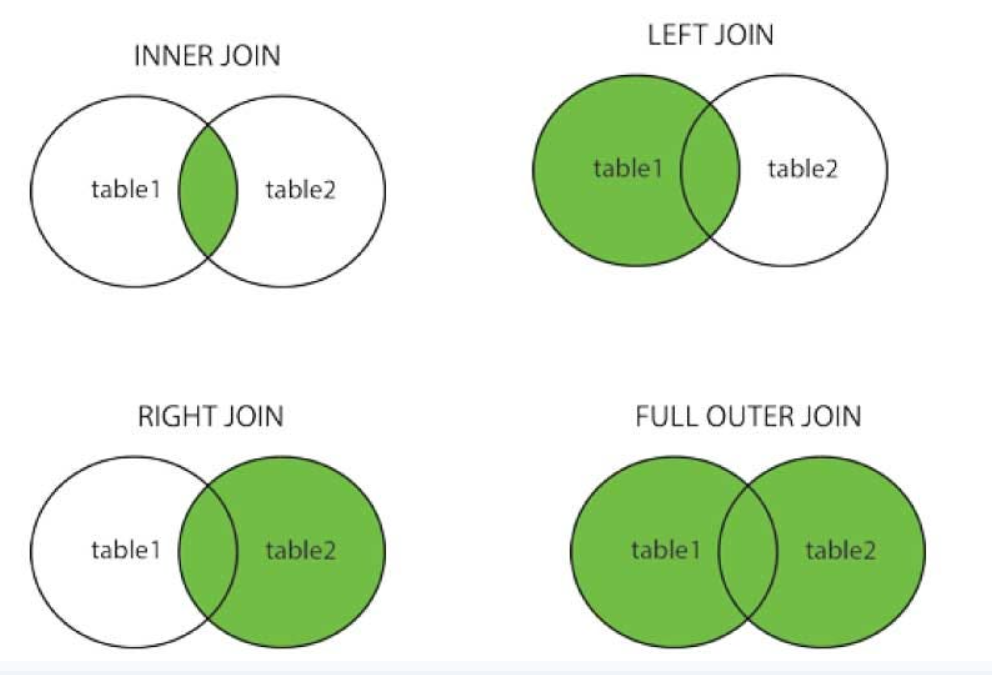

**syntax -**  df1.merge(df2, on='common column name')

In [119]:
users.merge(msgs, on='userid')                  # this is inner join
                                                # by default it applies inner join

,userid,name,msg
0,1,jack,yes
1,1,jack,okay
2,2,eliza,alright


**Inner Join**

In [120]:
users.merge(msgs, on='userid', how='inner')    # 'how' parameter decides the type of join

,userid,name,msg
0,1,jack,yes
1,1,jack,okay
2,2,eliza,alright


**Left Join**

In [121]:
users.merge(msgs, on='userid', how='left')

,userid,name,msg
0,1,jack,yes
1,1,jack,okay
2,2,eliza,alright
3,3,tom,NaN


**Right Join**

In [122]:
users.merge(msgs, on='userid', how='right')

,userid,name,msg
0,1,jack,yes
1,1,jack,okay
2,2,eliza,alright
3,4,NaN,nice


**Full Outer Join**

In [123]:
users.merge(msgs, on='userid', how='outer') 

,userid,name,msg
0,1,jack,yes
1,1,jack,okay
2,2,eliza,alright
3,3,tom,NaN
4,4,NaN,nice


##### if column names are different then -

In [124]:
# forcefully i am changing the column name
users.rename({'userid':'user_id'}, axis=1, inplace=True)
users

,user_id,name
0,1,jack
1,2,eliza
2,3,tom


In [125]:
# users.merge(msgs, on='userid', how='inner')        # this will throw an error

In [126]:
# joining the two tables with different column names
users.merge(msgs, left_on='user_id', right_on='userid', how='inner')

,user_id,name,userid,msg
0,1,jack,1,yes
1,1,jack,1,okay
2,2,eliza,2,alright


In [127]:
users.merge(msgs, left_on='user_id', right_on='userid', how='outer')

,user_id,name,userid,msg
0,1.0,jack,1.0,yes
1,1.0,jack,1.0,okay
2,2.0,eliza,2.0,alright
3,3.0,tom,NaN,NaN
4,NaN,NaN,4.0,nice


In [128]:
# interchanging the tables and merging
msgs.merge(users, left_on='userid', right_on='user_id', how='left')

,userid,msg,user_id,name
0,1,yes,1.0,jack
1,1,okay,1.0,jack
2,2,alright,2.0,eliza
3,4,nice,NaN,NaN


#### Grouping

In [129]:
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [130]:
df = sns.load_dataset('tips')

In [131]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [132]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


##### Applying groupby() method to group the dataframe

**syntax -** df.groupby('column name')

In [133]:
df.groupby('sex')

In [134]:
group = df.groupby('sex')
group

In [135]:
# For viewing the group, we can use loop
for g in group:
    print(g)

('Male',      total_bill   tip   sex smoker  day    time  size
1         10.34  1.66  Male     No  Sun  Dinner     3
2         21.01  3.50  Male     No  Sun  Dinner     3
3         23.68  3.31  Male     No  Sun  Dinner     2
5         25.29  4.71  Male     No  Sun  Dinner     4
6          8.77  2.00  Male     No  Sun  Dinner     2
..          ...   ...   ...    ...  ...     ...   ...
236       12.60  1.00  Male    Yes  Sat  Dinner     2
237       32.83  1.17  Male    Yes  Sat  Dinner     2
239       29.03  5.92  Male     No  Sat  Dinner     3
241       22.67  2.00  Male    Yes  Sat  Dinner     2
242       17.82  1.75  Male     No  Sat  Dinner     2

[157 rows x 7 columns])
('Female',      total_bill   tip     sex smoker   day    time  size
0         16.99  1.01  Female     No   Sun  Dinner     2
4         24.59  3.61  Female     No   Sun  Dinner     4
11        35.26  5.00  Female     No   Sun  Dinner     4
14        14.83  3.02  Female     No   Sun  Dinner     2
16        10.33  1.67 

**Creating groups (separating the data) on the basis of smoker column**

In [136]:
group2 = df.groupby('smoker')

In [137]:
for g in group2:
    print(g)

('Yes',      total_bill   tip     sex smoker  day    time  size
56        38.01  3.00    Male    Yes  Sat  Dinner     4
58        11.24  1.76    Male    Yes  Sat  Dinner     2
60        20.29  3.21    Male    Yes  Sat  Dinner     2
61        13.81  2.00    Male    Yes  Sat  Dinner     2
62        11.02  1.98    Male    Yes  Sat  Dinner     2
..          ...   ...     ...    ...  ...     ...   ...
234       15.53  3.00    Male    Yes  Sat  Dinner     2
236       12.60  1.00    Male    Yes  Sat  Dinner     2
237       32.83  1.17    Male    Yes  Sat  Dinner     2
240       27.18  2.00  Female    Yes  Sat  Dinner     2
241       22.67  2.00    Male    Yes  Sat  Dinner     2

[93 rows x 7 columns])
('No',      total_bill   tip     sex smoker   day    time  size
0         16.99  1.01  Female     No   Sun  Dinner     2
1         10.34  1.66    Male     No   Sun  Dinner     3
2         21.01  3.50    Male     No   Sun  Dinner     3
3         23.68  3.31    Male     No   Sun  Dinner     2
4   

In [138]:
# displaying the number of groups created
df.groupby('sex').ngroups

2

In [139]:
df.groupby('smoker').ngroups

2

In [144]:
df.groupby('day').ngroups

4

In [145]:
# for visualizing a single group without loop
df.groupby('sex').get_group('Male')

,total_bill,tip,sex,smoker,day,time,size
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
5,25.29,4.71,Male,No,Sun,Dinner,4
6,8.77,2.00,Male,No,Sun,Dinner,2
...,...,...,...,...,...,...,...
236,12.60,1.00,Male,Yes,Sat,Dinner,2
237,32.83,1.17,Male,Yes,Sat,Dinner,2
239,29.03,5.92,Male,No,Sat,Dinner,3
241,22.67,2.00,Male,Yes,Sat,Dinner,2


In [146]:
df.groupby('sex').get_group('Female')

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
11,35.26,5.00,Female,No,Sun,Dinner,4
14,14.83,3.02,Female,No,Sun,Dinner,2
16,10.33,1.67,Female,No,Sun,Dinner,3
...,...,...,...,...,...,...,...
226,10.09,2.00,Female,Yes,Fri,Lunch,2
229,22.12,2.88,Female,Yes,Sat,Dinner,2
238,35.83,4.67,Female,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
